In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.5 MB/s  0:00:14


# Task 08 — Cars Price Prediction (Regression)
**Goal:** predict the price of a used car. **Target:** `Price`. **Features:** Brand, Year, Mileage, Engine_Size, Fuel_Type, Transmission, Previous_Owners.

**Metrics:** MAE, MSE, RMSE and R². Prices are right-skewed, so the models are trained on `log(Price)` and the final errors are reported in dollars too.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

## 1. Load the data

In [3]:
import os
path = 'dataset/cars_data.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'cars_data.csv'
df = pd.read_csv(path)

In [4]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


In [5]:
df.shape

(1000, 8)

In [6]:
df.columns

Index(['Brand', 'Year', 'Mileage', 'Engine_Size', 'Fuel_Type', 'Transmission',
       'Previous_Owners', 'Price'],
      dtype='object')

In [7]:
df.describe()

,Year,Mileage,Engine_Size,Previous_Owners,Price
count,1000.000000,1000.000000,980.000000,1000.000000,1000.000000
mean,2016.300000,104551.675000,2.494592,3.062000,8473.646000
std,4.056162,56197.795061,0.865230,1.404325,6292.910864
min,2010.000000,5207.000000,1.000000,1.000000,3000.000000
25%,2013.000000,54239.250000,1.800000,2.000000,4069.500000
50%,2016.000000,105298.000000,2.500000,3.000000,6439.000000
75%,2020.000000,155468.250000,3.225000,4.000000,10905.500000
max,2023.000000,199812.000000,4.000000,5.000000,43994.000000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            1000 non-null   object 
 1   Year             1000 non-null   int64  
 2   Mileage          1000 non-null   int64  
 3   Engine_Size      980 non-null    float64
 4   Fuel_Type        1000 non-null   object 
 5   Transmission     1000 non-null   object 
 6   Previous_Owners  1000 non-null   int64  
 7   Price            1000 non-null   int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 62.6+ KB


## 2. Data cleaning

In [9]:
df.isnull().sum().sort_values(ascending=False).head(3)

,0
Engine_Size,20
Brand,0
Year,0


<Axes: xlabel='Engine_Size', ylabel='Count'>

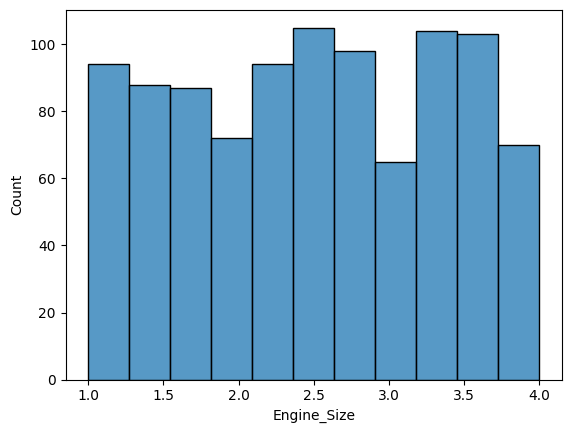

In [10]:
sns.histplot(data=df,x='Engine_Size')

**Missing values:** only `Engine_Size` (20 rows). The old code filled it with the mean of the whole data before splitting (leakage); now it is filled after the split with the median of the train data (see the split section).

In [11]:
# Engine_Size has a few missing values: they are filled AFTER the split with the median of the train data only
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values:
Engine_Size    20
dtype: int64


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
df.reset_index(drop=True,inplace=True)

In [15]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


## 3. EDA (visualization)

<Axes: xlabel='Transmission', ylabel='count'>

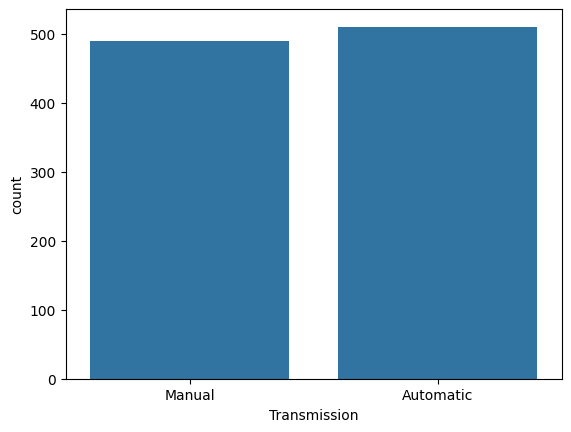

In [16]:
sns.countplot(x=df['Transmission'])

<Axes: xlabel='Transmission', ylabel='count'>

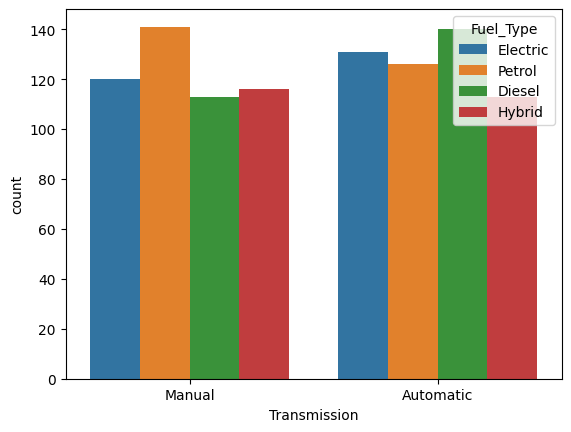

In [17]:
sns.countplot(x=df['Transmission'],hue=df['Fuel_Type'])

In [18]:
df.columns

Index(['Brand', 'Year', 'Mileage', 'Engine_Size', 'Fuel_Type', 'Transmission',
       'Previous_Owners', 'Price'],
      dtype='object')

<Axes: xlabel='Mileage', ylabel='Price'>

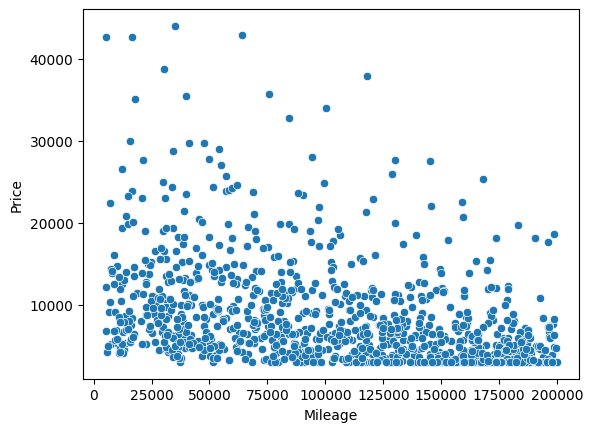

In [19]:
sns.scatterplot(data=df,x='Mileage',y='Price')

<Axes: xlabel='Mileage', ylabel='Price'>

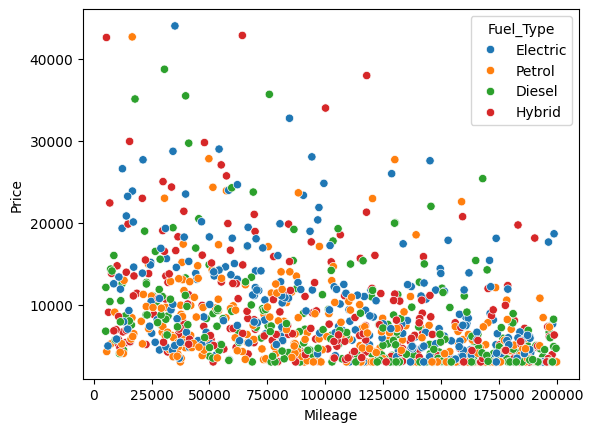

In [20]:
sns.scatterplot(data=df,x='Mileage',y='Price',hue='Fuel_Type')

<Axes: xlabel='Mileage', ylabel='Price'>

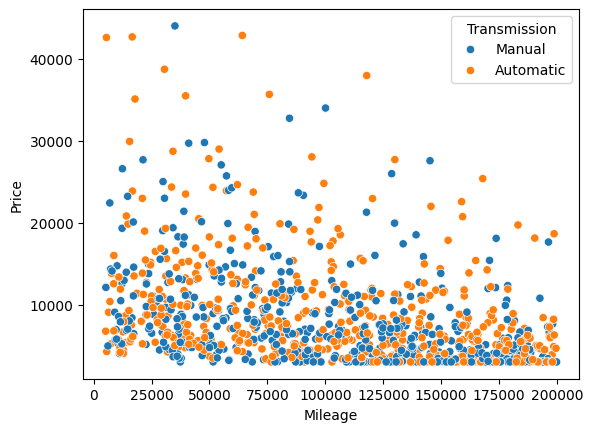

In [21]:
sns.scatterplot(data=df,x='Mileage',y='Price',hue='Transmission')

In [22]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


<Axes: xlabel='Engine_Size', ylabel='Price'>

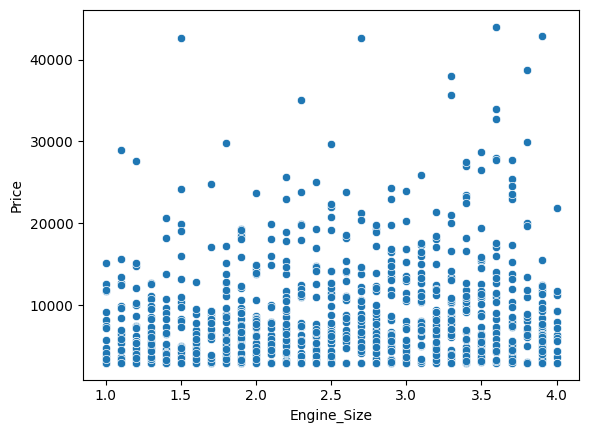

In [23]:
sns.scatterplot(data=df,x='Engine_Size',y='Price')

<Axes: xlabel='Mileage'>

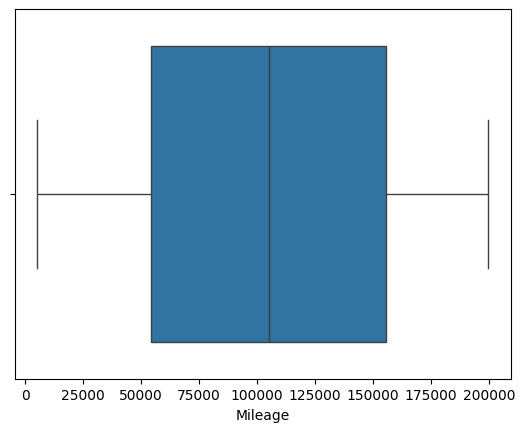

In [24]:
sns.boxplot(data=df,x='Mileage')

<Axes: >

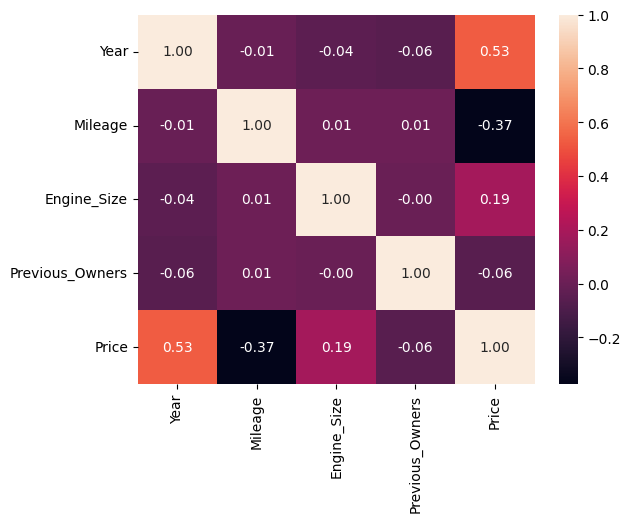

In [25]:
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt='0.2f')

<Axes: xlabel='Year', ylabel='Price'>

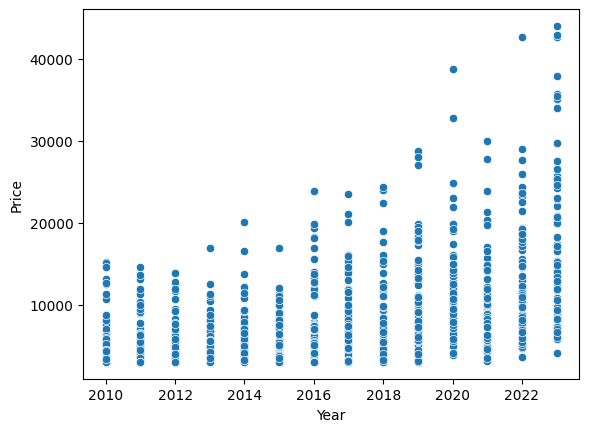

In [26]:
sns.scatterplot(data=df,x='Year',y='Price')

<Axes: xlabel='Year', ylabel='Price'>

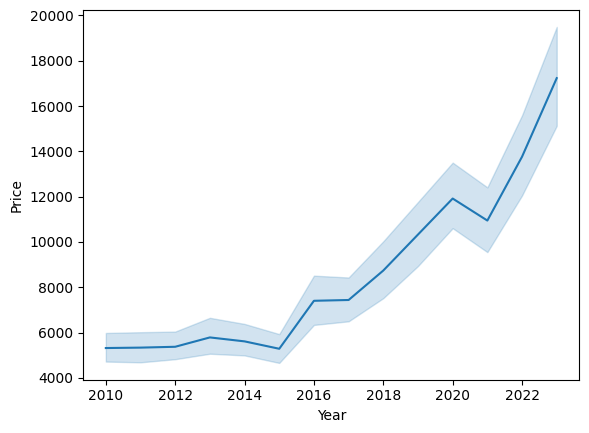

In [27]:
sns.lineplot(data=df,x='Year',y='Price')

<Axes: xlabel='Engine_Size', ylabel='Price'>

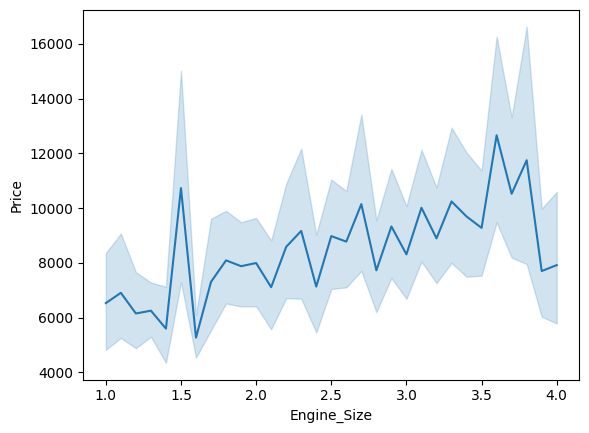

In [28]:
sns.lineplot(data=df,x='Engine_Size',y='Price')

<Axes: xlabel='Mileage', ylabel='Price'>

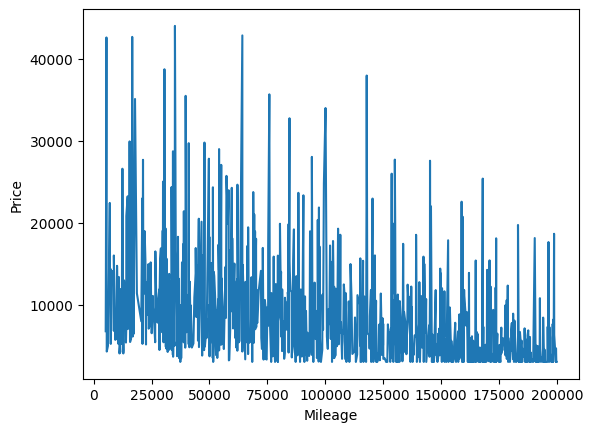

In [29]:
sns.lineplot(data=df,x='Mileage',y='Price')

In [30]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


<Axes: xlabel='Previous_Owners', ylabel='Price'>

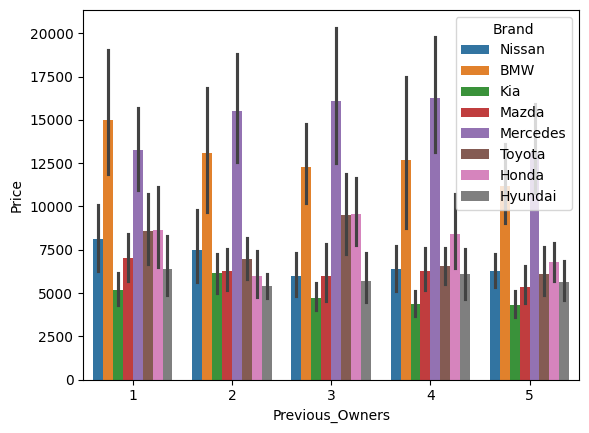

In [31]:
sns.barplot(data=df,x='Previous_Owners',y='Price',hue = 'Brand')

<Axes: xlabel='Brand', ylabel='Price'>

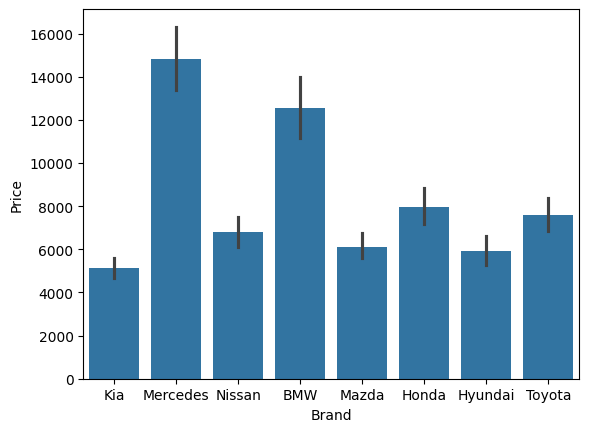

In [32]:
sns.barplot(data=df,x='Brand',y='Price')

<Axes: xlabel='Brand', ylabel='count'>

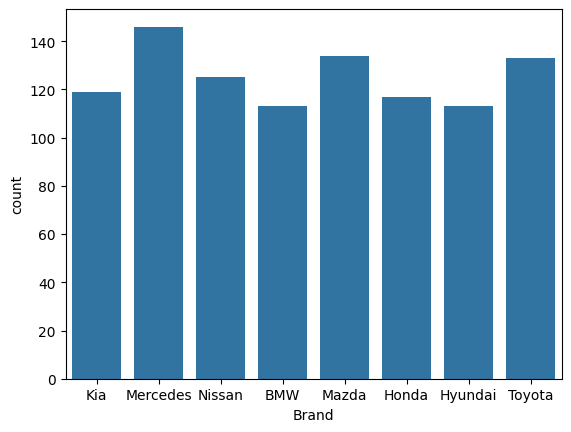

In [33]:
sns.countplot(x=df['Brand'])

<Axes: xlabel='Mileage', ylabel='Count'>

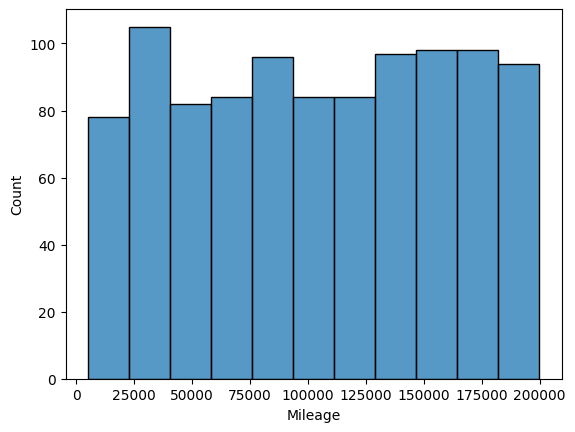

In [34]:
sns.histplot(x=df['Mileage'])

<Axes: xlabel='Price', ylabel='Count'>

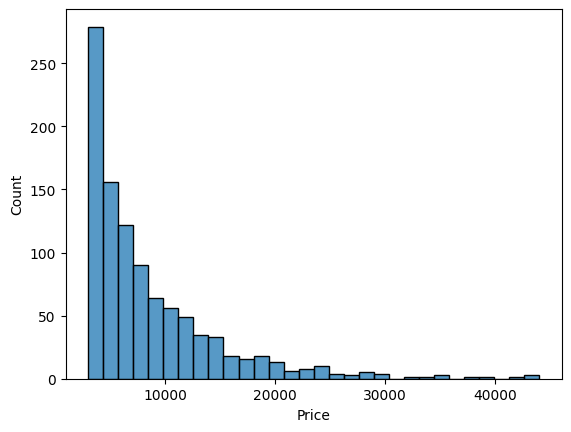

In [35]:
sns.histplot(x=df['Price'])

<Axes: xlabel='Price'>

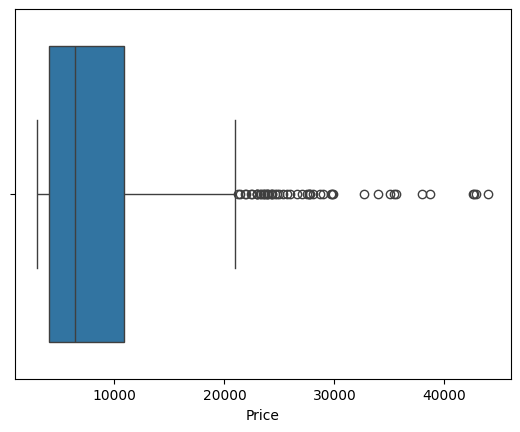

In [36]:
sns.boxplot(x=df['Price'])

### Outliers (IQR rule)

In [37]:
for col in ['Price', 'Mileage', 'Engine_Size']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / len(df) * 100:.1f}%)  [valid range {low:.1f} to {high:.1f}]  max = {df[col].max():.1f}")
print("Cars with Price >= 32000:", (df['Price'] >= 32000).sum(), "of", len(df))

Price: 49 outliers (4.9%)  [valid range -6184.5 to 21159.5]  max = 43994.0
Mileage: 0 outliers (0.0%)  [valid range -97604.2 to 307311.8]  max = 199812.0
Engine_Size: 0 outliers (0.0%)  [valid range -0.3 to 5.4]  max = 4.0
Cars with Price >= 32000: 11 of 1000


**Decision:** `Mileage` and `Engine_Size` have no outliers. Only a few very expensive cars (price >= 32,000, about 1% of the data) are far from the others and there are too few of them for the model to learn from, so they are **removed** (next cells). The model is therefore meant for typical cars below 32,000. The remaining skew of the price is handled with `log1p` of the target.

In [38]:
df = df[df['Price']<40000]

<Axes: xlabel='Price'>

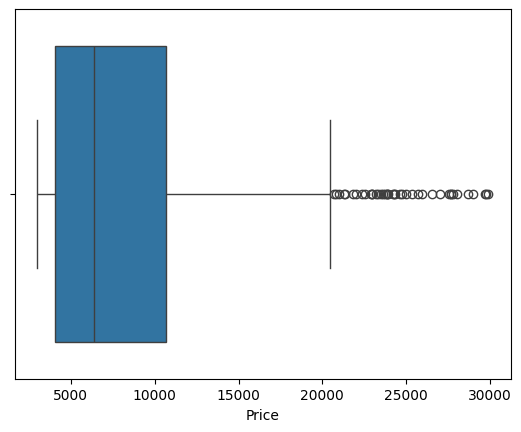

In [39]:
sns.boxplot(x=df[df['Price']<32000]['Price'])

In [40]:
df[df['Price']<32000]['Price'].shape

(989,)

In [41]:
df = df[df['Price']<32000]

In [42]:
df.shape

(989, 8)

In [43]:
df.reset_index(drop=True,inplace=True)

## 4. Encoding
Brand and Fuel_Type are one-hot encoded (the categories are fixed, so this is safe before the split); Transmission is label encoded.

In [44]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 989 entries, 0 to 988
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            989 non-null    object 
 1   Year             989 non-null    int64  
 2   Mileage          989 non-null    int64  
 3   Engine_Size      970 non-null    float64
 4   Fuel_Type        989 non-null    object 
 5   Transmission     989 non-null    object 
 6   Previous_Owners  989 non-null    int64  
 7   Price            989 non-null    int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 61.9+ KB


In [46]:
df['Brand'].nunique()

8

In [47]:
df['Fuel_Type'].unique()

array(['Electric', 'Petrol', 'Diesel', 'Hybrid'], dtype=object)

In [48]:
df['Transmission'].unique()

array(['Manual', 'Automatic'], dtype=object)

In [49]:
onehot = OneHotEncoder()

In [50]:
New = onehot.fit_transform(df[['Brand']]).toarray()
New

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.]], shape=(989, 8))

In [51]:
onehot.categories_[0]

array(['BMW', 'Honda', 'Hyundai', 'Kia', 'Mazda', 'Mercedes', 'Nissan',
       'Toyota'], dtype=object)

In [52]:
for index,col in enumerate(onehot.categories_[0]):
    df[col]=New[:,index]

In [53]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price,BMW,Honda,Hyundai,Kia,Mazda,Mercedes,Nissan,Toyota
0,Kia,2015,110373,2.5,Electric,Manual,2,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [54]:
df.drop('Brand',axis = 1 ,inplace=True)

In [55]:
New1 = onehot.fit_transform(df[['Fuel_Type']]).toarray()
New1

array([[0., 1., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 0., 1.],
       ...,
       [0., 0., 1., 0.],
       [1., 0., 0., 0.],
       [0., 0., 0., 1.]], shape=(989, 4))

In [56]:
New1=pd.DataFrame(New1,columns=onehot.categories_[0])
New1.head()

,Diesel,Electric,Hybrid,Petrol
0,0.0,1.0,0.0,0.0
1,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0


In [57]:
df=pd.concat([df,New1],axis=1)

In [58]:
df.head()

,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price,BMW,Honda,Hyundai,Kia,Mazda,Mercedes,Nissan,Toyota,Diesel,Electric,Hybrid,Petrol
0,2015,110373,2.5,Electric,Manual,2,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2010,186144,1.3,Electric,Manual,5,4844,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2018,29574,2.6,Petrol,Manual,1,6628,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,2010,139502,2.4,Diesel,Automatic,4,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2014,148748,3.5,Diesel,Manual,1,6451,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [59]:
df.drop('Fuel_Type',axis=1,inplace=True)

In [60]:
lable_encoding =LabelEncoder()

In [61]:
df['Transmission'] =lable_encoding.fit_transform(df['Transmission'])

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 989 entries, 0 to 988
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             989 non-null    int64  
 1   Mileage          989 non-null    int64  
 2   Engine_Size      970 non-null    float64
 3   Transmission     989 non-null    int64  
 4   Previous_Owners  989 non-null    int64  
 5   Price            989 non-null    int64  
 6   BMW              989 non-null    float64
 7   Honda            989 non-null    float64
 8   Hyundai          989 non-null    float64
 9   Kia              989 non-null    float64
 10  Mazda            989 non-null    float64
 11  Mercedes         989 non-null    float64
 12  Nissan           989 non-null    float64
 13  Toyota           989 non-null    float64
 14  Diesel           989 non-null    float64
 15  Electric         989 non-null    float64
 16  Hybrid           989 non-null    float64
 17  Petrol          

In [63]:
df.head()

,Year,Mileage,Engine_Size,Transmission,Previous_Owners,Price,BMW,Honda,Hyundai,Kia,Mazda,Mercedes,Nissan,Toyota,Diesel,Electric,Hybrid,Petrol
0,2015,110373,2.5,1,2,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2010,186144,1.3,1,5,4844,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2018,29574,2.6,1,1,6628,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,2010,139502,2.4,0,4,3000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2014,148748,3.5,1,1,6451,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## 5. Train / Test split

In [64]:
y=df['Price']

In [65]:
X=df.drop('Price',axis=1)

In [66]:
from sklearn.model_selection import train_test_split

In [67]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,shuffle=True)

### Fill missing `Engine_Size` (median of the train data only) and log of the target

In [68]:
from sklearn.impute import SimpleImputer

X_train = X_train.copy()
X_test = X_test.copy()

imputer = SimpleImputer(strategy='median')
X_train[['Engine_Size']] = imputer.fit_transform(X_train[['Engine_Size']])
X_test[['Engine_Size']] = imputer.transform(X_test[['Engine_Size']])
print("Missing values left:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

# Price is right-skewed -> the models are trained on log(Price); the real prices are kept for the final evaluation
y_train_real, y_test_real = y_train.copy(), y_test.copy()
y_train = np.log1p(y_train_real)
y_test = np.log1p(y_test_real)

Missing values left: 0 0


## 6. Scaling (fit on train only)

In [69]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler

In [70]:
scaler = MinMaxScaler()

In [71]:
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

## 7. All the models
All models of the track are trained on the log target and evaluated on the test set (errors on the log scale).

In [72]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [73]:
from sklearn.linear_model import ElasticNet
models["ElasticNet"] = ElasticNet()

In [74]:
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/16 [00:00<?, ?it/s]

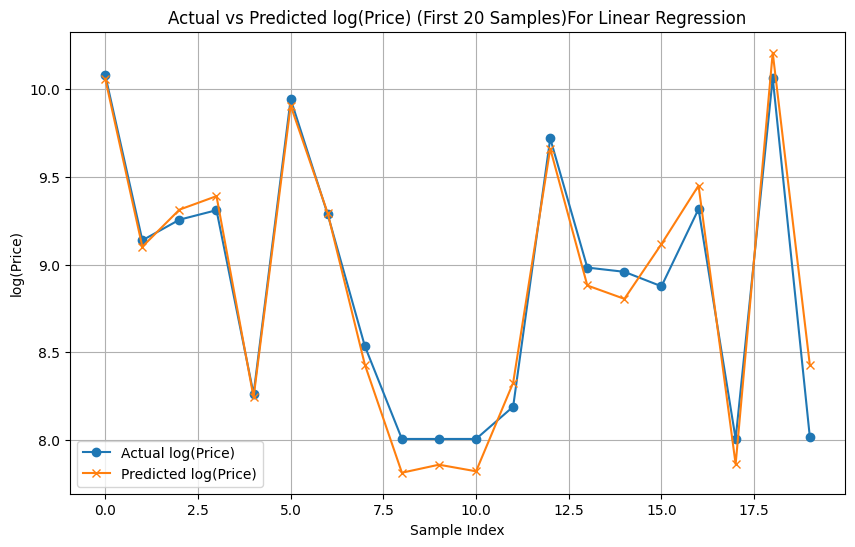

  6%|▋         | 1/16 [00:00<00:10,  1.46it/s]

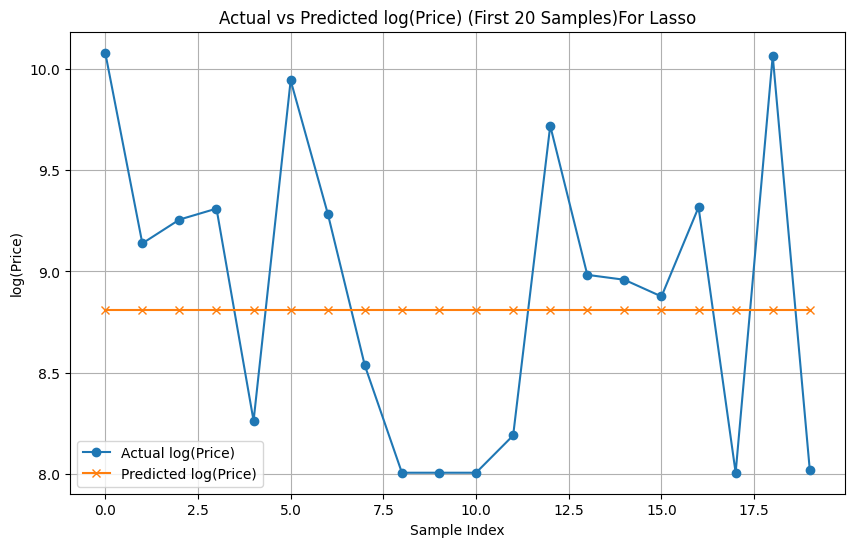

 12%|█▎        | 2/16 [00:01<00:08,  1.73it/s]

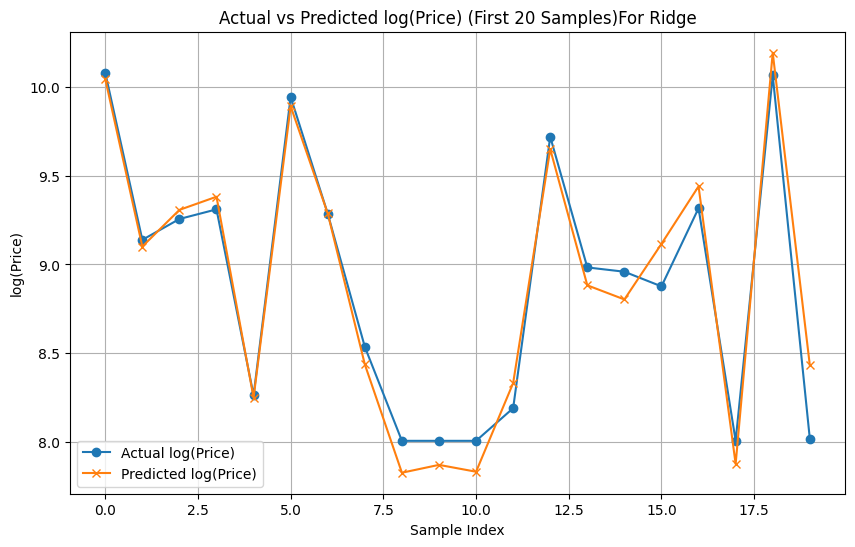

 19%|█▉        | 3/16 [00:01<00:07,  1.70it/s]

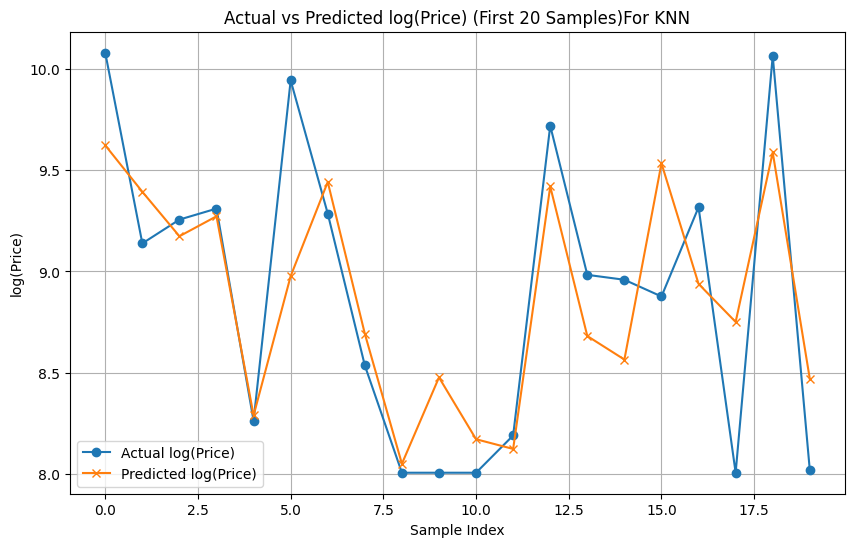

 25%|██▌       | 4/16 [00:02<00:07,  1.62it/s]

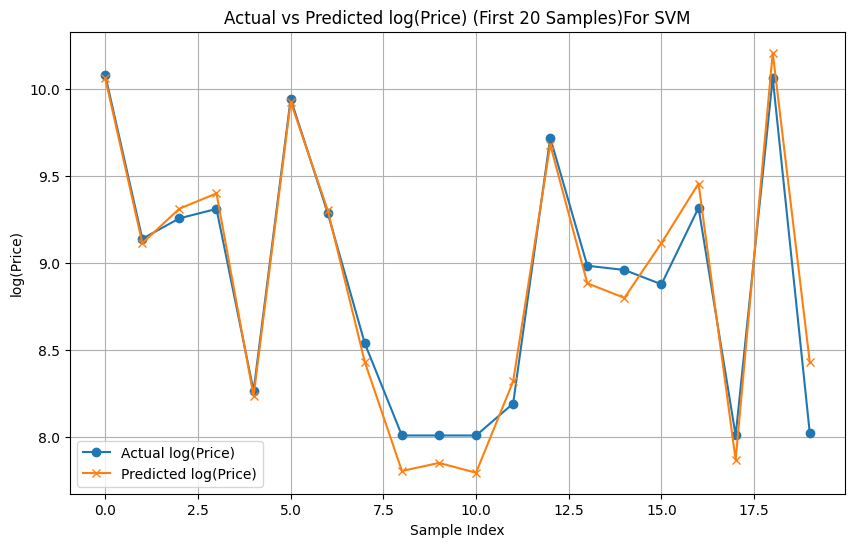

 31%|███▏      | 5/16 [00:02<00:06,  1.69it/s]

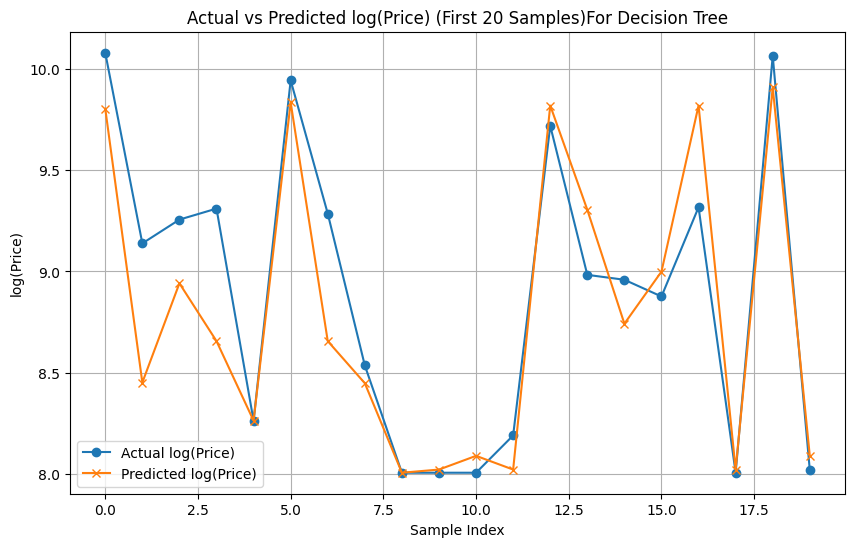

 38%|███▊      | 6/16 [00:03<00:05,  1.69it/s]

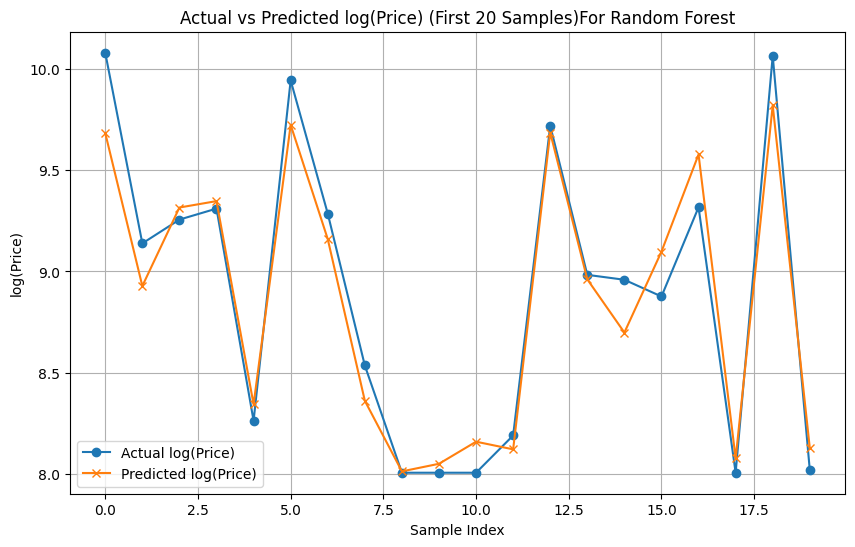

 44%|████▍     | 7/16 [00:05<00:08,  1.07it/s]

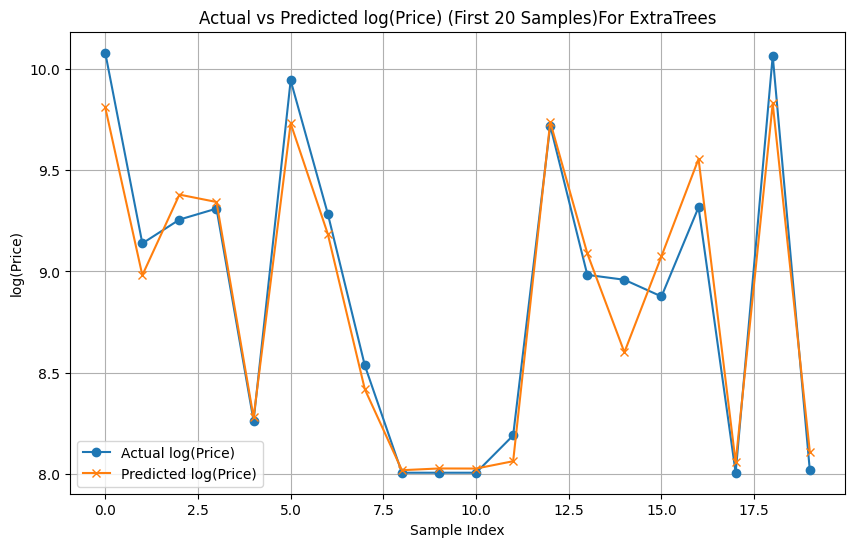

 50%|█████     | 8/16 [00:07<00:12,  1.50s/it]

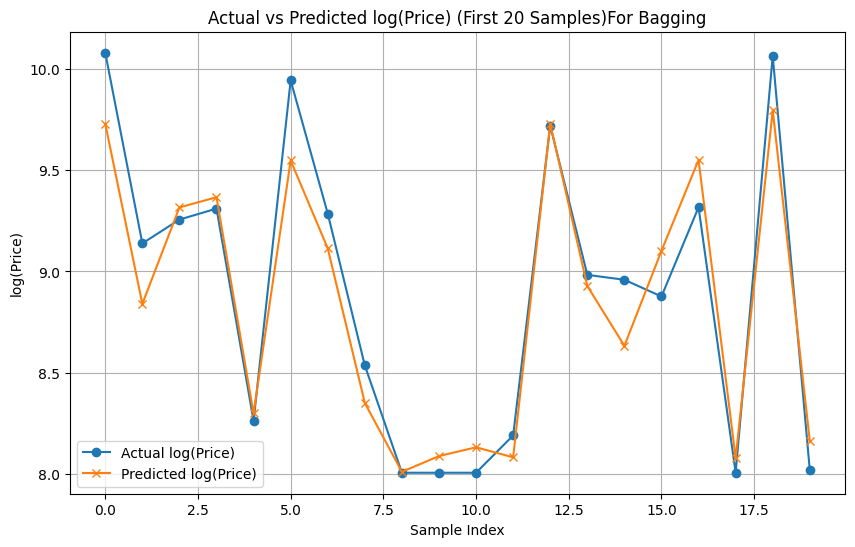

 56%|█████▋    | 9/16 [00:09<00:09,  1.43s/it]

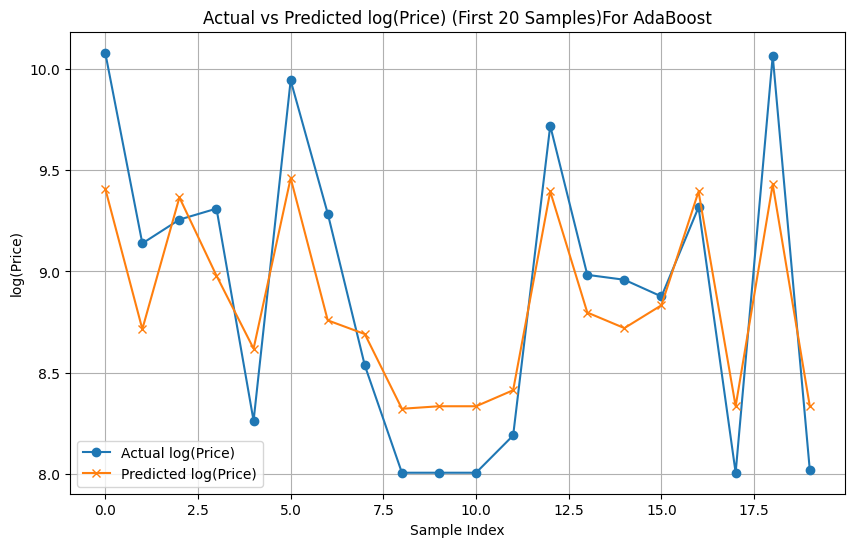

 62%|██████▎   | 10/16 [00:09<00:07,  1.18s/it]

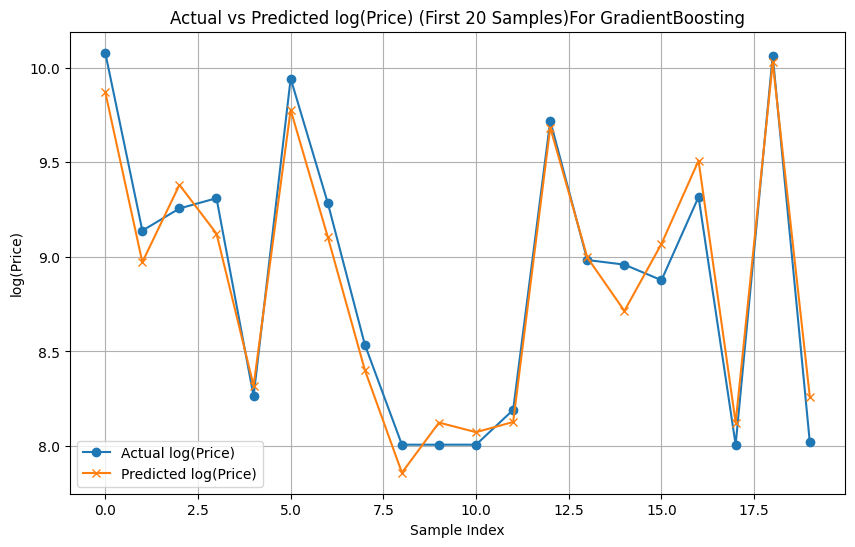

 69%|██████▉   | 11/16 [00:10<00:05,  1.06s/it]

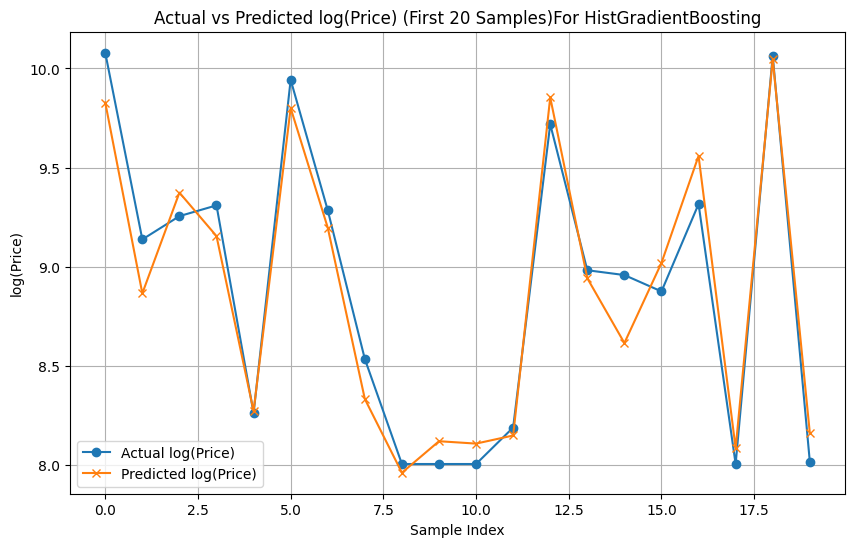

 75%|███████▌  | 12/16 [00:12<00:04,  1.21s/it]

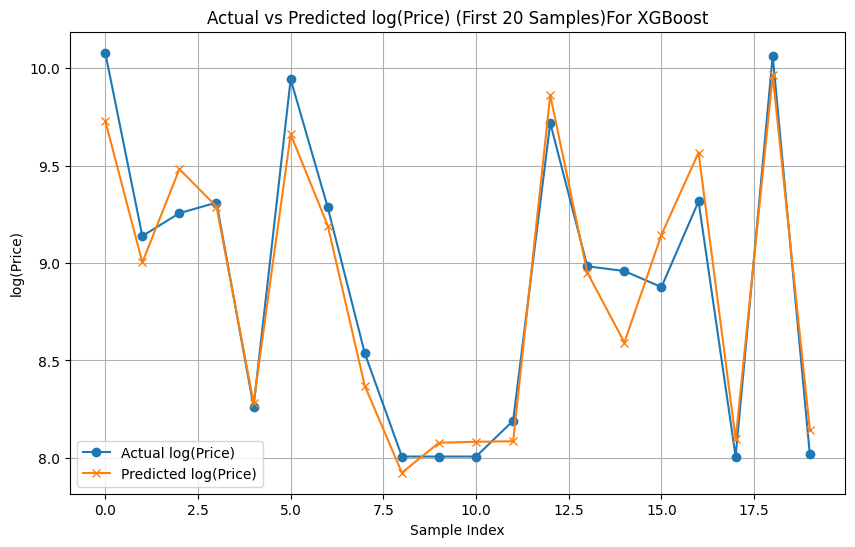

 81%|████████▏ | 13/16 [00:13<00:03,  1.14s/it]

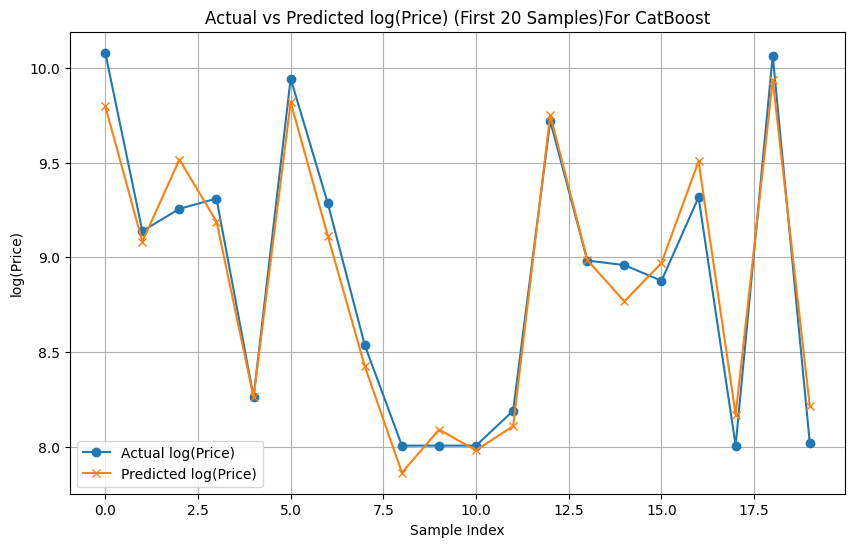

 88%|████████▊ | 14/16 [00:13<00:01,  1.11it/s]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001840 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 331
[LightGBM] [Info] Number of data points in the train set: 791, number of used features: 17
[LightGBM] [Info] Start training from score 8.808449
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

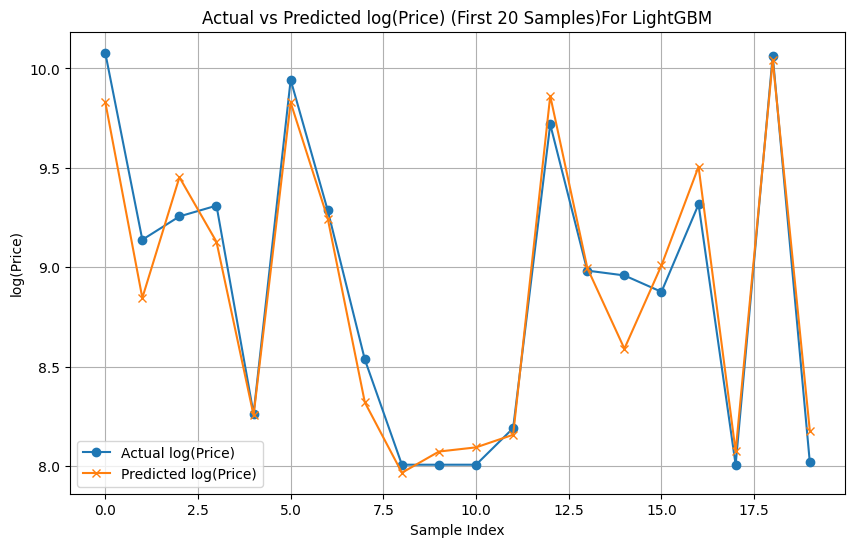

 94%|█████████▍| 15/16 [00:13<00:00,  1.38it/s]

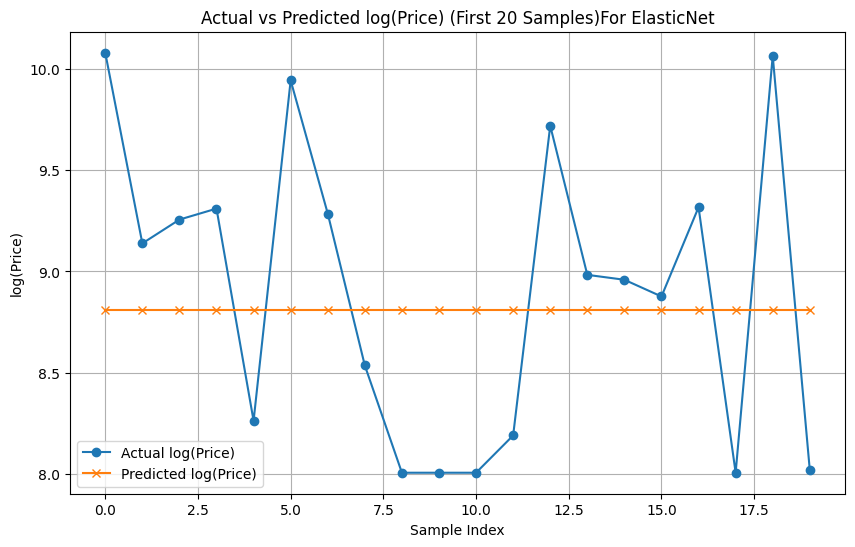

100%|██████████| 16/16 [00:14<00:00,  1.14it/s]


In [75]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual log(Price)', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted log(Price)', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('log(Price)')
    plt.title('Actual vs Predicted log(Price) (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [76]:
# Voting regressors (averaging). The old 'Simple Voting' was identical to 'Voting', so it is kept once.
def add_errors(name, model):
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model, X_test, y_test)
    errors[name] = {
        "MAE Train": MAE_Train, "MAE Test": MAE_Test,
        "MSE Train": MSE_Train, "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train, "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train, "R2 Test": R2_Test
    }

clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

model1 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)])
model3 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], weights=[2, 1, 2])

model1.fit(X_train, y_train)
model3.fit(X_train, y_train)

add_errors("Voting", model1)
add_errors("Weighted Voting", model3)

In [77]:
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=XGBRegressor(),
    cv=5,
    passthrough=True,
    n_jobs=-1
)

stacking_regressor.fit(X_train, y_train)
add_errors("Stacking", stacking_regressor)

In [78]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [79]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
CatBoost,7.723306e-02,0.110665,8.535058e-03,0.018856,9.238538e-02,0.137316,0.976124,0.949870
Stacking,6.220228e-02,0.112919,7.072135e-03,0.022652,8.409599e-02,0.150506,0.980216,0.939776
HistGradientBoosting,5.141492e-02,0.120227,4.031136e-03,0.023614,6.349123e-02,0.153668,0.988723,0.937219
GradientBoosting,8.806392e-02,0.125051,1.147110e-02,0.023620,1.071032e-01,0.153689,0.967910,0.937202
LightGBM,5.029246e-02,0.120632,3.925093e-03,0.024520,6.265057e-02,0.156590,0.989020,0.934809
XGBoost,2.849117e-02,0.135506,1.474911e-03,0.030320,3.840457e-02,0.174127,0.995874,0.919389
ExtraTrees,1.167994e-14,0.136084,1.660258e-28,0.031913,1.288510e-14,0.178641,1.000000,0.915155
Voting,5.977712e-02,0.148157,5.473502e-03,0.035233,7.398312e-02,0.187705,0.984688,0.906328
Weighted Voting,6.293494e-02,0.150118,6.189961e-03,0.035757,7.867630e-02,0.189096,0.982684,0.904934
Linear Regression,1.396973e-01,0.155273,3.116905e-02,0.036511,1.765476e-01,0.191080,0.912806,0.902929


<Axes: >

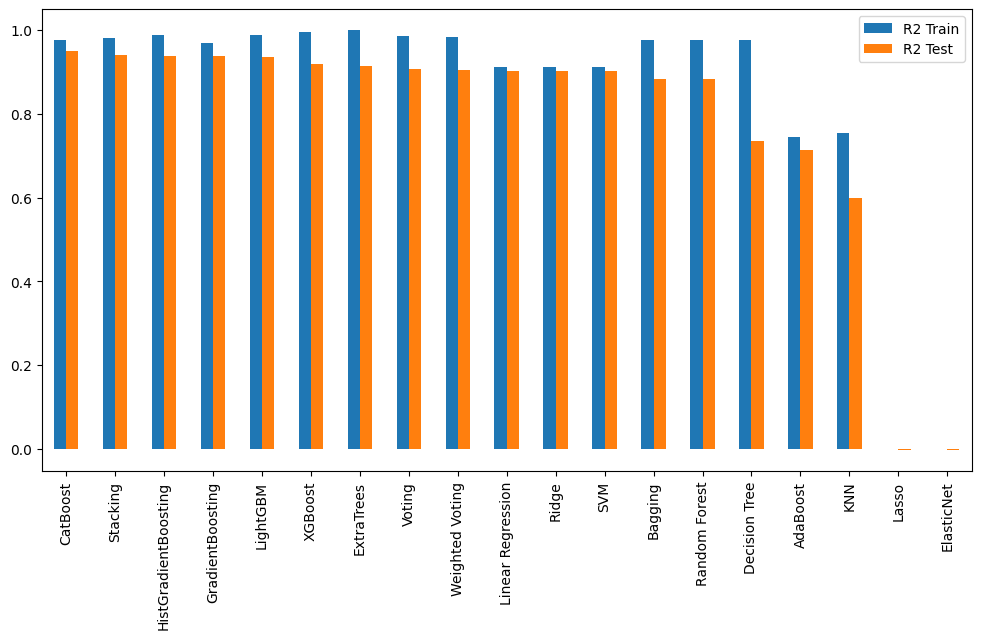

In [80]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

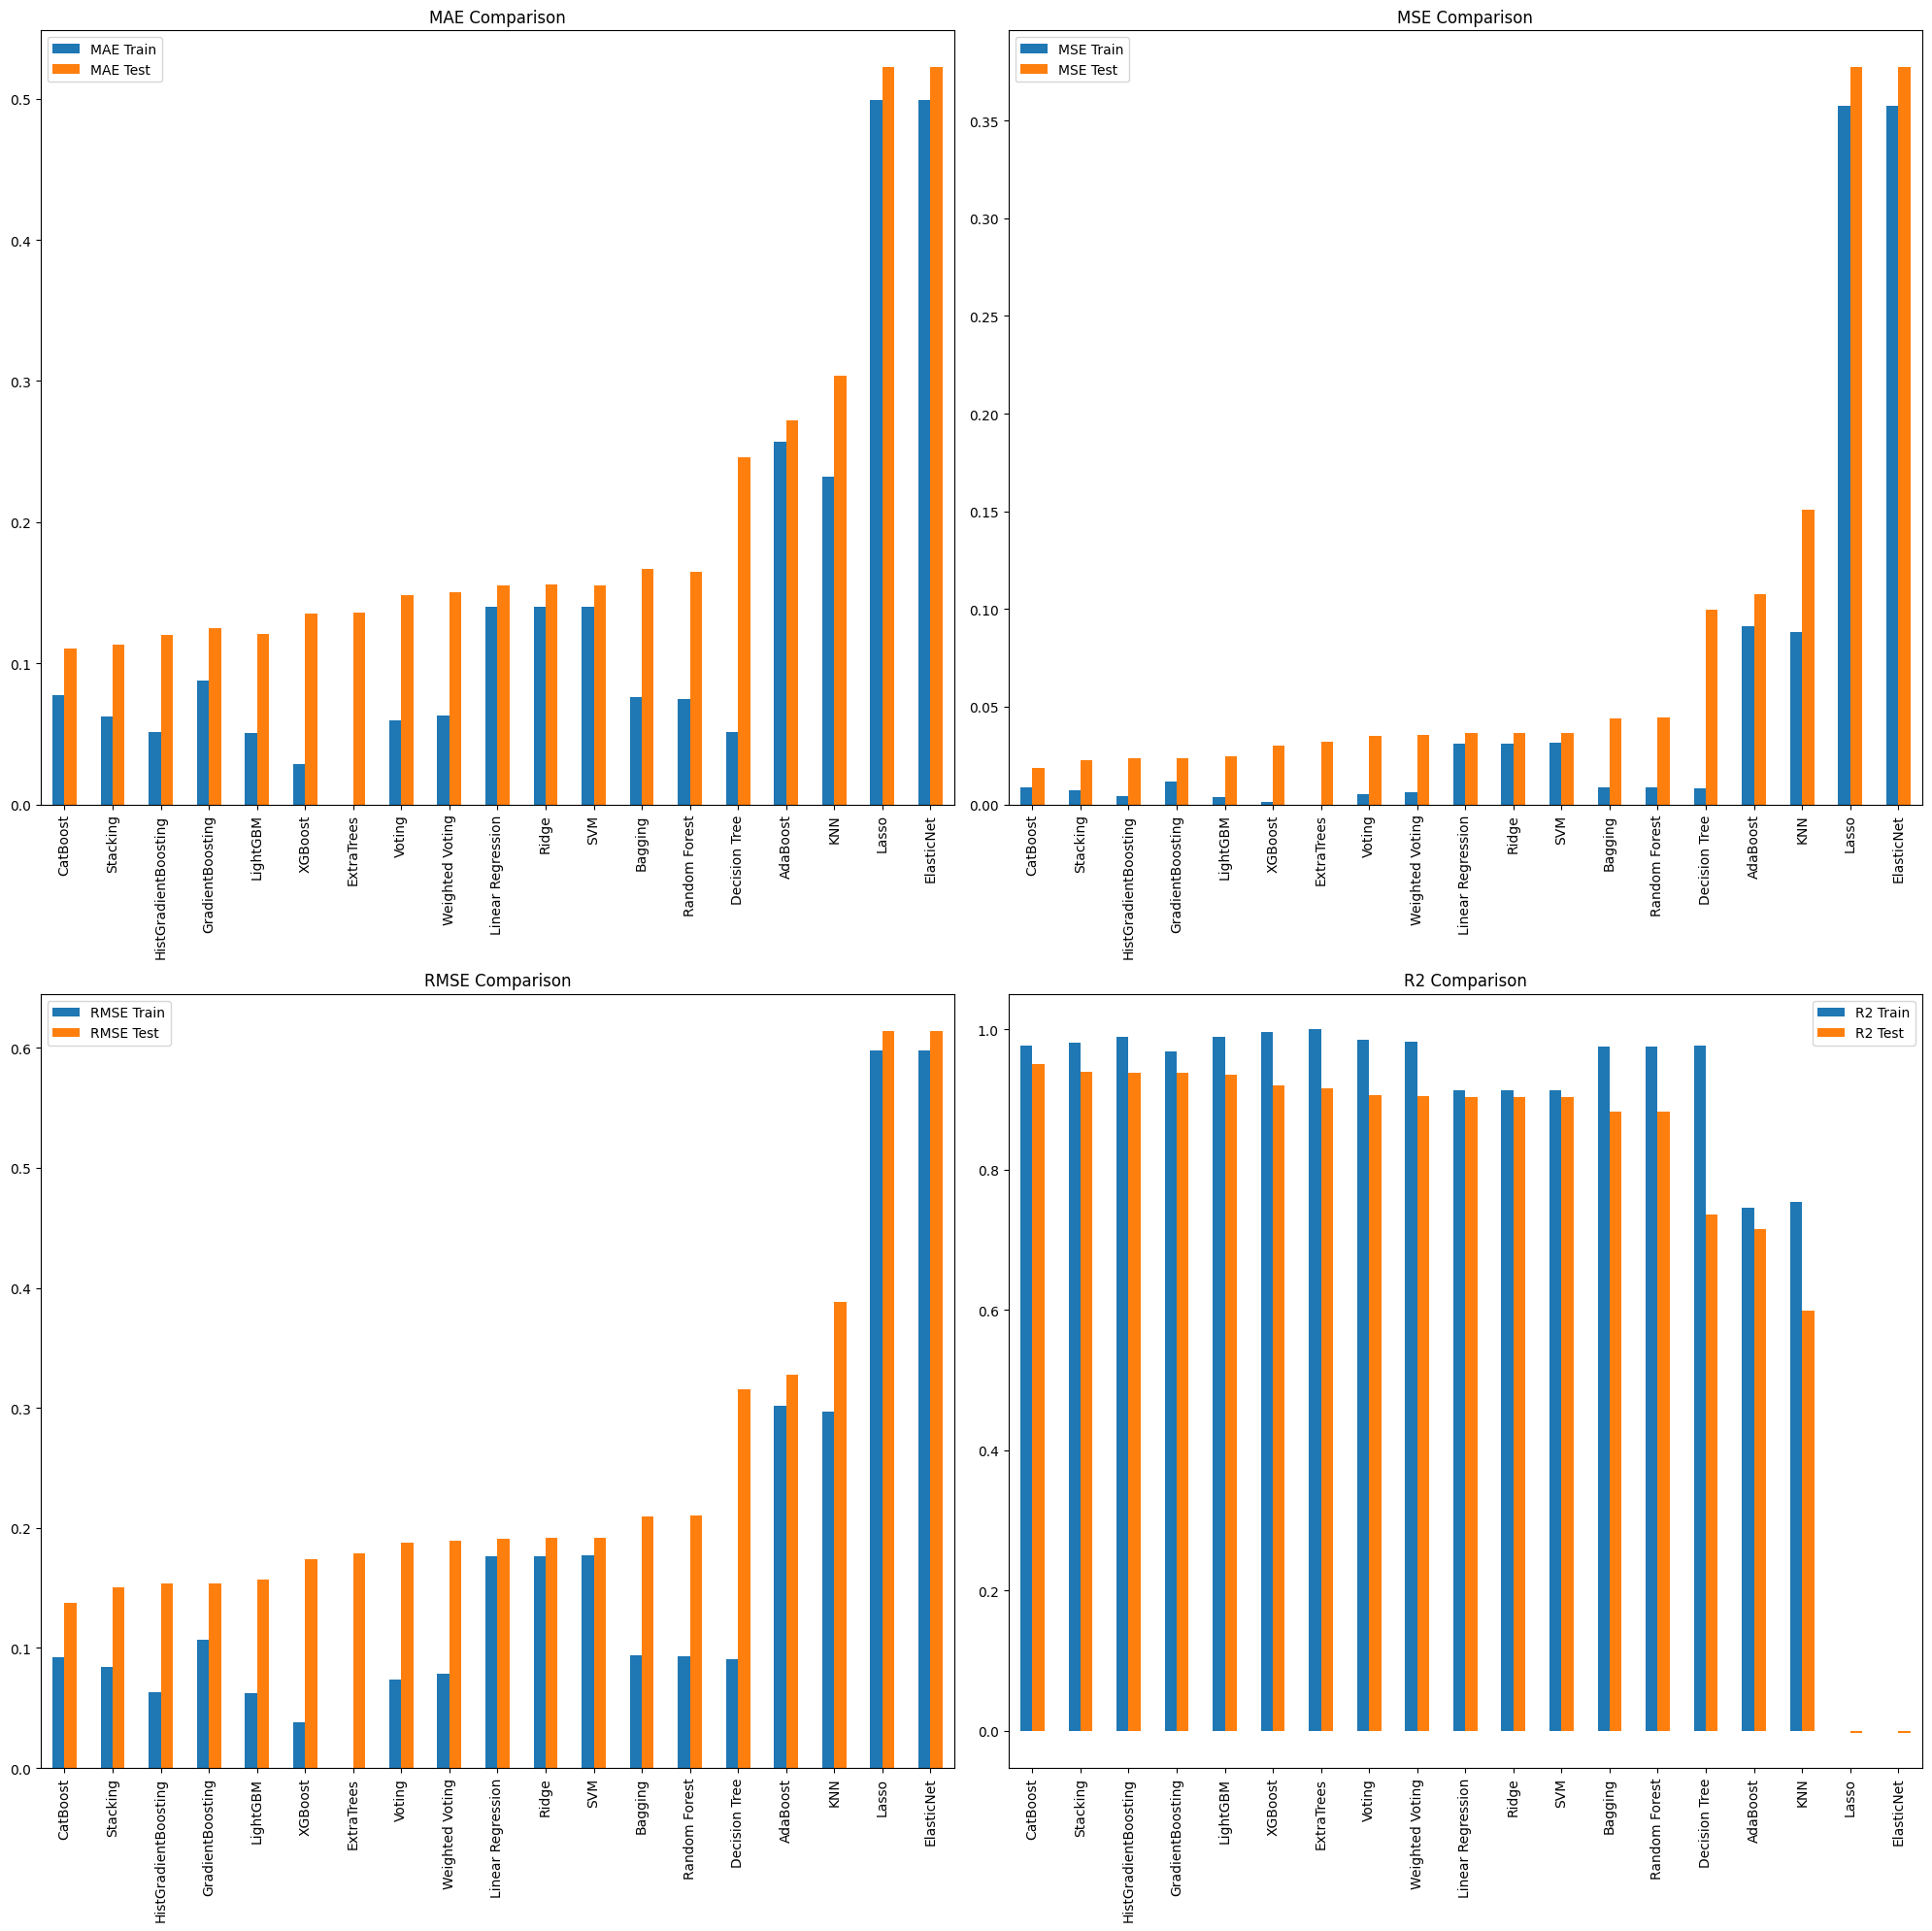

In [81]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** the table above uses the test set to show how each model behaves (errors are on the **log(price)** scale). To **choose** and **tune** the final model we do not use the test set: we use cross-validation on the training data (next sections). Large gaps between Train and Test R² mean overfitting (e.g. Decision Tree, ExtraTrees, Random Forest).

## 9. Model comparison with Cross-Validation (train data only)
5-fold cross-validation on the training data, metric **R²** (and RMSE on log(price)).

In [82]:
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.base import clone

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for name, model in tqdm(models.items()):
    cv = cross_validate(clone(model), X_train, y_train, cv=kf, n_jobs=-1,
                        scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'})
    cv_rows[name] = {'CV R2': cv['test_r2'].mean(), 'CV RMSE (log)': -cv['test_rmse'].mean()}

cv_df = pd.DataFrame(cv_rows).T.sort_values('CV R2', ascending=False)
cv_df

100%|██████████| 16/16 [00:07<00:00,  2.02it/s]


,CV R2,CV RMSE (log)
CatBoost,0.941800,0.143175
LightGBM,0.933993,0.152867
HistGradientBoosting,0.932818,0.154274
GradientBoosting,0.925070,0.162375
Linear Regression,0.906988,0.181230
Ridge,0.906763,0.181438
SVM,0.906150,0.182040
XGBoost,0.905111,0.183094
ExtraTrees,0.898108,0.190008
Bagging,0.870456,0.213994


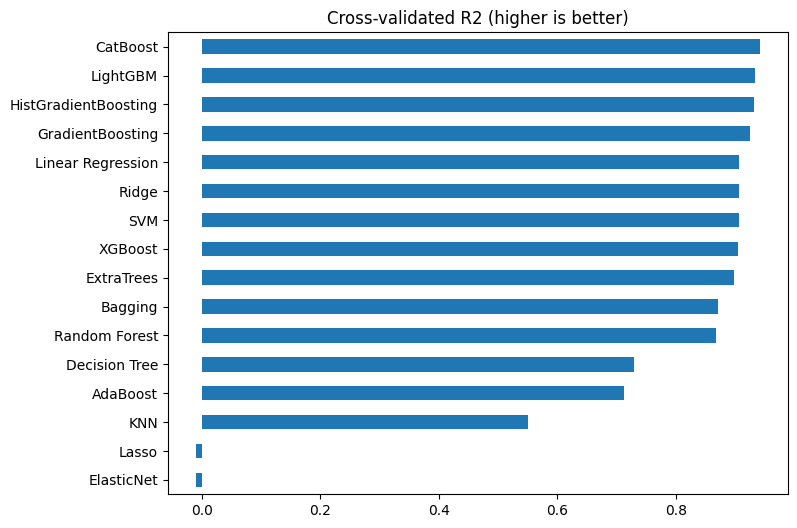

In [83]:
cv_df['CV R2'].sort_values().plot.barh(figsize=(8, 6))
plt.title('Cross-validated R2 (higher is better)')
plt.show()

## 10. GridSearchCV on the best 3 models
The top 3 models of the cross-validation comparison are tuned with `GridSearchCV` (5-fold, metric R², training data only).

In [84]:
param_grids = {
    'Linear Regression': {'fit_intercept': [True, False]},
    'Lasso': {'alpha': [0.0001, 0.0005, 0.001, 0.01]},
    'Ridge': {'alpha': [1, 3, 10, 30, 100]},
    'ElasticNet': {'alpha': [0.0005, 0.001, 0.01], 'l1_ratio': [0.2, 0.5, 0.8]},
    'KNN': {'n_neighbors': [3, 5, 9, 15], 'weights': ['uniform', 'distance']},
    'SVM': {'C': [0.1, 1], 'epsilon': [0.01, 0.1]},
    'Decision Tree': {'max_depth': [4, 6, 10], 'min_samples_leaf': [1, 5, 10]},
    'Random Forest': {'n_estimators': [100, 300], 'max_depth': [10, None], 'min_samples_leaf': [1, 3]},
    'ExtraTrees': {'n_estimators': [100, 300], 'max_depth': [10, None], 'min_samples_leaf': [1, 3]},
    'Bagging': {'n_estimators': [50, 100], 'max_samples': [0.7, 1.0]},
    'AdaBoost': {'n_estimators': [50, 100, 200], 'learning_rate': [0.05, 0.1, 0.5]},
    'GradientBoosting': {'n_estimators': [200, 500], 'learning_rate': [0.03, 0.1], 'max_depth': [2, 3]},
    'HistGradientBoosting': {'max_iter': [200, 400], 'learning_rate': [0.03, 0.1], 'max_depth': [None, 4]},
    'XGBoost': {'n_estimators': [300, 600], 'max_depth': [2, 3], 'learning_rate': [0.03, 0.1]},
    'CatBoost': {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.03, 0.1]},
    'LightGBM': {'n_estimators': [300, 600], 'num_leaves': [8, 15], 'learning_rate': [0.03, 0.1]},
}

top3 = cv_df.head(3).index.tolist()
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    grid = GridSearchCV(clone(models[name]), param_grids[name], cv=kf, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 4))
    summary.append([name, cv_df.loc[name, 'CV R2'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning (CV R2)', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['CatBoost', 'LightGBM', 'HistGradientBoosting']

CatBoost
  best_params_: {'depth': 4, 'iterations': 600, 'learning_rate': 0.03}
  best_score_ : 0.9506
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000062 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 331
[LightGBM] [Info] Number of data points in the train set: 791, number of used features: 17
[LightGBM] [Info] Start training from score 8.808449

LightGBM
  best_params_: {'learning_rate': 0.1, 'n_estimators': 300, 'num_leaves': 8}
  best_score_ : 0.9419

HistGradientBoosting
  best_params_: {'learning_rate': 0.1, 'max_depth': 4, 'max_iter': 200}
  best_score_ : 0.9366


,Before tuning (CV R2),After tuning (best_score_)
Model,,
CatBoost,0.941800,0.950595
LightGBM,0.933993,0.941912
HistGradientBoosting,0.932818,0.936642


**Why these parameters:** `alpha` is the regularization strength of the linear models; depth / leaf size control overfitting of the trees; `learning_rate` and the number of trees trade off in boosting; `n_neighbors` controls the smoothness of KNN. The grids are small on purpose to keep the search fast.

## 11. Final model and evaluation on the test set (used once)

In [85]:
best_name = tuning_df['After tuning (best_score_)'].idxmax()
best_model = tuned[best_name].best_estimator_          # already refitted on the whole train data
print("Best model:", best_name, tuned[best_name].best_params_)

pred_log = best_model.predict(X_test)
pred_real = np.expm1(pred_log)
y_real = y_test_real          # real prices of the test rows

results = pd.DataFrame({
    'log(price)': [mean_absolute_error(y_test, pred_log), mean_squared_error(y_test, pred_log),
                       np.sqrt(mean_squared_error(y_test, pred_log)), r2_score(y_test, pred_log)],
    'Real price ($)': [mean_absolute_error(y_real, pred_real), mean_squared_error(y_real, pred_real),
                       np.sqrt(mean_squared_error(y_real, pred_real)), r2_score(y_real, pred_real)],
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
results

Best model: CatBoost {'depth': 4, 'iterations': 600, 'learning_rate': 0.03}


,log(price),Real price ($)
MAE,0.109400,9.680713e+02
MSE,0.017464,2.075207e+06
RMSE,0.132151,1.440558e+03
R2,0.953570,9.346629e-01


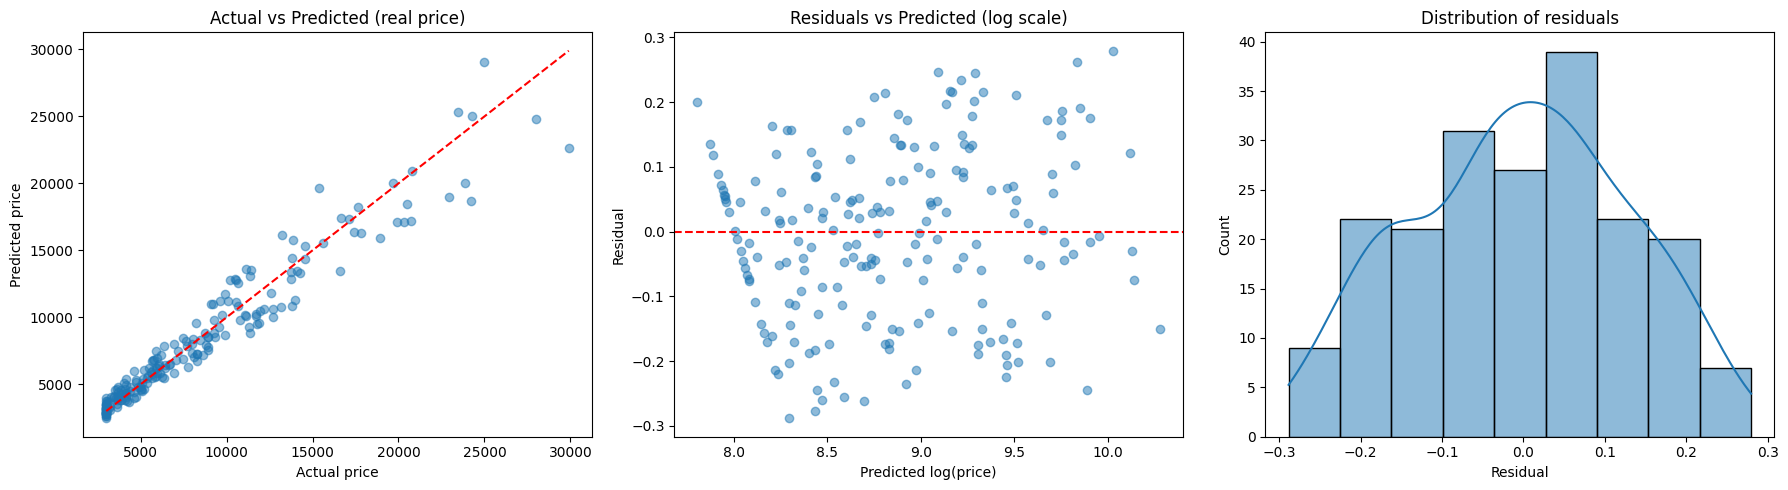

In [86]:
residuals = y_test - pred_log          # log scale
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_real, pred_real, alpha=0.5)
lim = [y_real.min(), y_real.max()]
axes[0].plot(lim, lim, 'r--')
axes[0].set_title('Actual vs Predicted (real price)')
axes[0].set_xlabel('Actual price'); axes[0].set_ylabel('Predicted price')

axes[1].scatter(pred_log, residuals, alpha=0.5)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('Residuals vs Predicted (log scale)')
axes[1].set_xlabel('Predicted log(price)'); axes[1].set_ylabel('Residual')

sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set_title('Distribution of residuals')
axes[2].set_xlabel('Residual')
plt.tight_layout()
plt.show()

In [87]:
errors_pct = np.abs(pred_real - y_real) / y_real * 100
print("=== Automatic interpretation of the results ===")
print(f"- Selected model: {best_name}.")
print(f"- R2 = {results.loc['R2', 'Real price ($)']:.3f} on the real price (and {results.loc['R2', 'log(price)']:.3f} on the log scale): "
      f"the model explains {results.loc['R2', 'Real price ($)']:.0%} of the variation of the price.")
print(f"- Typical error: MAE = ${results.loc['MAE', 'Real price ($)']:,.0f}; median error = {np.median(errors_pct):.1f}% of the real price; "
      f"RMSE = ${results.loc['RMSE', 'Real price ($)']:,.0f} (bigger because expensive cars count more).")
print(f"- {np.mean(errors_pct < 10):.0%} of the cars are predicted within 10% of the real price.")
print(f"- Mean residual (log) = {residuals.mean():.3f} (close to 0 means no systematic over/under prediction).")
print(f"- The top 3 models differ by only {tuning_df['After tuning (best_score_)'].max() - tuning_df['After tuning (best_score_)'].min():.3f} in CV R2.")

=== Automatic interpretation of the results ===
- Selected model: CatBoost.
- R2 = 0.935 on the real price (and 0.954 on the log scale): the model explains 93% of the variation of the price.
- Typical error: MAE = $968; median error = 9.3% of the real price; RMSE = $1,441 (bigger because expensive cars count more).
- 52% of the cars are predicted within 10% of the real price.
- Mean residual (log) = -0.005 (close to 0 means no systematic over/under prediction).
- The top 3 models differ by only 0.014 in CV R2.


**Interpretation**
- **R² (real price)** tells how much of the price variation is explained; **MAE** is the average error in dollars; **RMSE / MSE** punish the big errors of expensive cars more.
- **Actual vs Predicted:** points near the red diagonal are good predictions; expensive cars are harder because there are few of them.
- **Residuals vs Predicted:** a random cloud around 0 is what we want; a curve or funnel would show a missing pattern or errors that grow with the price.
- **Histogram of residuals:** bell-shaped and centred on 0 means balanced errors.
- **Limits:** the dataset has only 1,000 cars and 7 features (no model name, condition or accident history), and the 11 most expensive cars (price >= 32,000) were removed, so the model is for typical cars below that price.

## 12. Conclusions
- Missing `Engine_Size` values are filled with the median of the train data only (after the split); scaling uses train data only.
- Training on `log(price)` and `log1p` of the skewed features make the models work well on this skewed data.
- The final model was chosen with cross-validation, tuned with `GridSearchCV`, and evaluated on the test set once.
- Possible improvements: feature engineering (e.g. car age = 2025 - Year), more tuning.